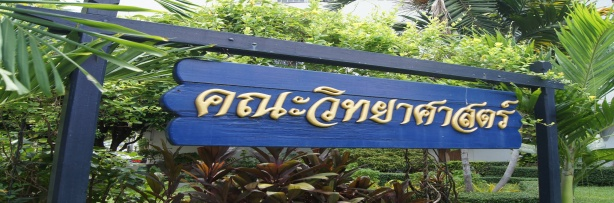

### <span style='color:lightgreen;'>Otsu Algorithm สำหรับ Image Thresholding</span>

**Otsu Algorithm** เป็นวิธีหา threshold แบบอัตโนมัติสำหรับภาพ grayscale โดยเลือกค่า `T` ที่แยก pixel ออกเป็น 2 กลุ่มได้ดีที่สุด คือกลุ่มมืดและกลุ่มสว่าง

แนวคิดสำคัญคือ ถ้าเลือก threshold ดี ค่า pixel ในแต่ละกลุ่มควรอยู่ใกล้กัน และค่าเฉลี่ยของสองกลุ่มควรห่างกันพอสมควร Otsu จึงเลือก `T` ที่ทำให้ **between-class variance** หรือความแตกต่างระหว่างสองกลุ่มมีค่าสูงสุด

จากรูปอธิบายเดิม ภาพรวมของ Otsu คือทดลองค่า threshold หลายค่า แล้ววัดว่าค่าใดแยก foreground กับ background ได้ดีที่สุด

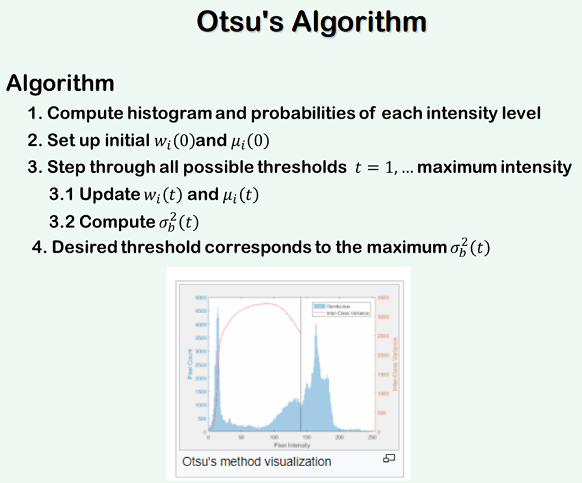

วิธีนี้เหมาะกับภาพที่ histogram มีแนวโน้มแยกเป็นสองกลุ่ม เช่น ภาพเอกสาร ภาพวัตถุบนพื้นหลังเรียบ หรือภาพที่ foreground/background มีความสว่างต่างกันชัดเจน


#### <span style='color:lightblue;'>Workflow ของบทเรียน</span>

ใน worksheet นี้จะนำเสนอ Otsu แบบกระชับ ไม่ซ้ำขั้นตอนเดิมหลายรอบ

1. เตรียม library และฟังก์ชันที่จำเป็น
2. อ่านภาพ grayscale ตัวอย่างเดิม และ resize ให้เหมาะกับการทดลอง
3. คำนวณและแสดง histogram
4. ทดลองคำนวณ Otsu score ของ threshold หนึ่งค่า
5. วนหา threshold ที่ให้ score สูงสุด
6. สร้าง binary image และตรวจผลเทียบกับ `cv2.threshold()`
7. เสริมตัวอย่างสั้น ๆ เพื่อเปรียบเทียบ threshold ที่เลือกเองกับ threshold จาก Otsu


1. **<span style='color:lightgreen;'>Import Libraries และ Function Names</span>**

ชื่อตัวแปรและฟังก์ชันในบทนี้ตั้งให้สั้น แต่ยังสื่อความหมายตรงประเด็น

- `show_img()` แสดงภาพ grayscale
- `hist_gray()` คำนวณ histogram
- `plot_hist()` แสดง histogram และเส้น threshold
- `score_T()` คำนวณ Otsu score ของค่า `T` หนึ่งค่า
- `otsu()` หา threshold ที่ดีที่สุด
- `to_bin()` แปลงภาพ grayscale เป็น binary image

สัญลักษณ์หลักใน code

- `T` คือ threshold
- `hist` คือ histogram
- `p` คือ probability ของ histogram
- `w0`, `w1` คือสัดส่วน pixel ของกลุ่มที่ 0 และกลุ่มที่ 1  w0 คือผลรวมของ ความน่าจะเป็นในช่อง h0 ไม่ต้องหา w1 เพราะ ความน่าจะเป็นทั้งหมด เท่ากับ 1 ดังนั้นถาหา w0 ได้ เราก็แค่เอามา 1- w0  จะได้ w1
- `m0`, `m1` คือค่าเฉลี่ย intensity ของแต่ละกลุ่ม
- `sb` คือ between-class variance หรือ Otsu score  (ค่าสูง = threashold)


In [5]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (6, 4)


In [6]:
def show_img(img, title="Grayscale Image"):
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")
    plt.show()


def hist_gray(img):
    return np.bincount(img.ravel(), minlength=256)


def plot_hist(hist, T=None, title="Histogram"):
    plt.figure(figsize=(7, 3))
    plt.plot(hist, color="black")
    if T is not None:
        plt.axvline(T, color="red", linestyle="--", label=f"T = {T}")
        plt.legend()
    plt.title(title)
    plt.xlabel("Pixel intensity (0 = black, 255 = white)")
    plt.ylabel("Number of pixels")
    plt.xlim([0, 255])
    plt.grid(alpha=0.2)
    plt.show()


def score_T(hist, T):
    T = int(np.clip(round(T), 0, 255))
    p = hist / hist.sum()
    levels = np.arange(256)

    p0 = p[:T + 1]
    p1 = p[T + 1:]
    w0 = p0.sum()
    w1 = p1.sum()

    if w0 == 0 or w1 == 0:
        return 0, {"w0": w0, "w1": w1, "m0": np.nan, "m1": np.nan}

    m0 = np.dot(levels[:T + 1], p0) / w0
    m1 = np.dot(levels[T + 1:], p1) / w1
    sb = w0 * w1 * (m0 - m1) ** 2 #ความแปรปรวนระหว่างกลุ่ม 

    return sb, {"w0": w0, "w1": w1, "m0": m0, "m1": m1}


def otsu(hist):
    scores = np.zeros(256)
    best_T = 0
    best_sb = -1

    for T in range(1, 255):
        sb, _ = score_T(hist, T)
        scores[T] = sb
        if sb > best_sb:
            best_sb = sb
            best_T = T

    return best_T, scores


def to_bin(img, T):
    out = np.zeros_like(img, dtype=np.uint8)
    out[img > T] = 255
    return out


2. **<span style='color:lightgreen;'>Read an Image</span>**

ตัวอย่างเดิมใช้ภาพ `bank4.jpg` ซึ่งเหมาะกับการทดลอง thresholding เพราะมีบริเวณสว่างและมืดให้แยกออกจากกัน

ในบทนี้อ่านภาพเป็น grayscale และใช้ภาพขนาดเดิมตาม worksheet เดิม เพราะ Otsu คำนวณจาก histogram โดยตรง หาก resize ภาพด้วย interpolation ค่า histogram จะเปลี่ยน และ threshold ที่ได้อาจเปลี่ยนตามไปด้วย


In [7]:
img_path = Path("../images/bank4.jpg")
img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(f"Cannot read image file: {img_path}")

print(f"Image loaded from: {img_path}")
print(f"Image shape: {img.shape}")
print(f"Data type: {img.dtype}")
print(f"Minimum intensity: {img.min()}")
print(f"Maximum intensity: {img.max()}")


Image loaded from: ..\images\bank4.jpg
Image shape: (514, 1200)
Data type: uint8
Minimum intensity: 0
Maximum intensity: 255


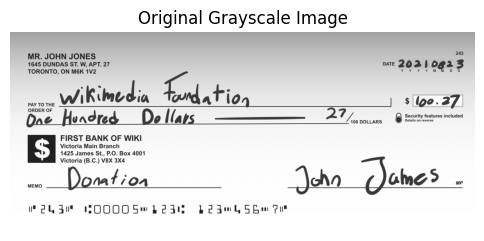

In [8]:
show_img(img, "Original Grayscale Image")


3. **<span style='color:lightgreen;'>Calculate and Plot Histogram</span>**

Histogram แสดงจำนวน pixel ในแต่ละระดับความสว่างตั้งแต่ `0` ถึง `255` สำหรับ Otsu histogram เป็นข้อมูลหลักที่ใช้ทดลองค่า threshold ทุกค่า

ถ้ากราฟมีสองกลุ่มค่อนข้างชัด ค่า threshold ที่ดีมักอยู่บริเวณช่องว่างหรือร่องระหว่างสองกลุ่มนั้น


Histogram bins: 256
Total pixels from histogram: 616,800
Total pixels from image: 616,800


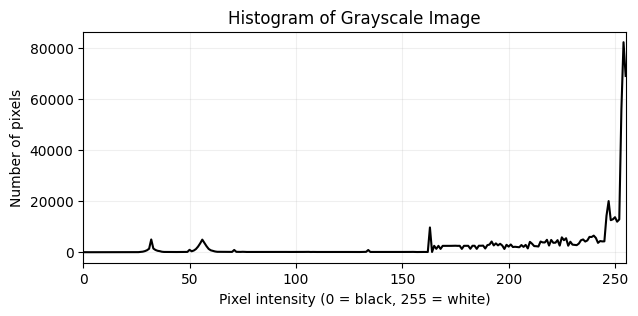

In [9]:
hist = hist_gray(img)

print(f"Histogram bins: {hist.shape[0]}")
print(f"Total pixels from histogram: {hist.sum():,}")
print(f"Total pixels from image: {img.size:,}")

plot_hist(hist, title="Histogram of Grayscale Image")


4. **<span style='color:lightgreen;'>Probability ของ Histogram</span>**

Otsu ไม่ได้ดูแค่จำนวน pixel ตรง ๆ แต่แปลง histogram เป็น probability ก่อน โดยนำจำนวน pixel ของแต่ละ intensity ไปหารด้วยจำนวน pixel ทั้งหมด

```text
p(i) = hist(i) / จำนวน pixel ทั้งหมด
```

ค่า `p(i)` จึงบอกว่า intensity ระดับ `i` มีสัดส่วนมากน้อยเพียงใดในภาพ

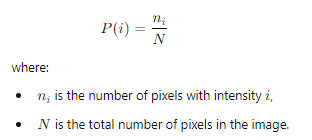


5. **<span style='color:lightgreen;'>แบ่ง Histogram เป็น 2 กลุ่มด้วย Threshold T</span>**

เมื่อกำหนด threshold `T` จะได้สองกลุ่ม

- กลุ่มที่ 0: pixel ที่มีค่า `<= T`
- กลุ่มที่ 1: pixel ที่มีค่า `> T`

`w0` และ `w1` คือสัดส่วน pixel ของแต่ละกลุ่ม ถ้ากลุ่มใดมีค่าน้อยมาก แปลว่า threshold นั้นอาจแบ่งภาพได้ไม่ดี

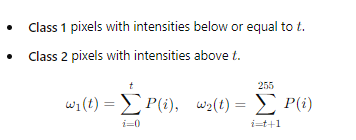


6. **<span style='color:lightgreen;'>ค่าเฉลี่ยของแต่ละกลุ่ม</span>**

หลังจากแบ่งกลุ่มแล้ว คำนวณค่าเฉลี่ย intensity ของแต่ละกลุ่ม

- `m0` คือค่าเฉลี่ยของกลุ่มที่ 0
- `m1` คือค่าเฉลี่ยของกลุ่มที่ 1

ถ้า `m0` และ `m1` ต่างกันมาก แปลว่ากลุ่มมืดและกลุ่มสว่างแยกจากกันชัดขึ้น (ใช้สูตรของ intermean ก็ได้ ทั้งสองใช้แทนกันได่้)

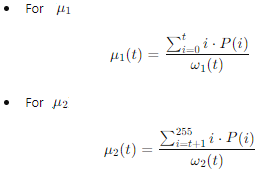


7. **<span style='color:lightgreen;'>Between-Class Variance หรือ Otsu Score</span>**

Otsu เลือก threshold ที่ทำให้ค่า between-class variance สูงสุด  <span style='color:lightgreen;'>ถ้าเราใช้สูตรของ intermean ตรงนี้ต้องทำให้อยู่ในรูปของความน่าจะเป็น</span>

```text
sb = w0 * w1 * (m0 - m1)^2   
```

ค่า `sb` สูง หมายถึงสองกลุ่มมีค่าเฉลี่ยห่างกันและแต่ละกลุ่มมีจำนวน pixel เพียงพอ จึงเป็น threshold ที่น่าสนใจ

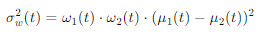


8. **<span style='color:lightgreen;'>ทดลองคำนวณ Otsu Score ของ Threshold หนึ่งค่า</span>**

ก่อนวนหา threshold ที่ดีที่สุด ลองเลือก `T = 100` เพื่อดูว่า code คำนวณอะไรบ้างในหนึ่งรอบของ Otsu


T: 100
w0: 0.0660
w1: 0.9340
m0: 51.86
m1: 231.24
Otsu score: 1982.60


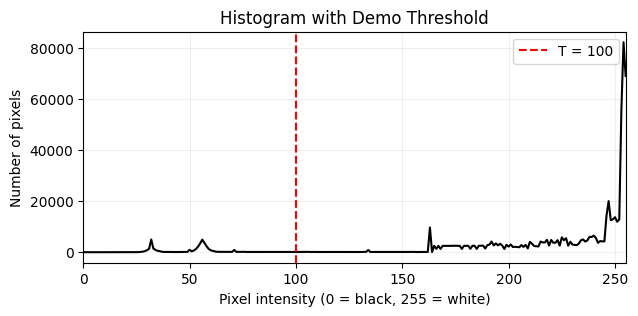

In [10]:
T_demo = 100
sb, info = score_T(hist, T_demo)  # should use in under loop Otsu 1-254 But this for show 1

print(f"T: {T_demo}")
print(f"w0: {info['w0']:.4f}")
print(f"w1: {info['w1']:.4f}")
print(f"m0: {info['m0']:.2f}")
print(f"m1: {info['m1']:.2f}")
print(f"Otsu score: {sb:.2f}")

plot_hist(hist, T=T_demo, title="Histogram with Demo Threshold")


9. **<span style='color:lightgreen;'>หา Threshold ที่ดีที่สุดด้วย Otsu</span>**

cell นี้วนค่า `T` ตั้งแต่ `1` ถึง `254` แล้วคำนวณ `sb` ของแต่ละค่า จากนั้นเลือก `T` ที่ทำให้ `sb` สูงที่สุด

การแสดงกราฟ `Otsu score` ช่วยให้นักศึกษาเห็นว่า algorithm เลือก threshold จากจุดสูงสุดของคะแนน ไม่ได้เลือกจากการเดาด้วยสายตา


Best threshold from Otsu: 146
Maximum Otsu score: 2043.95


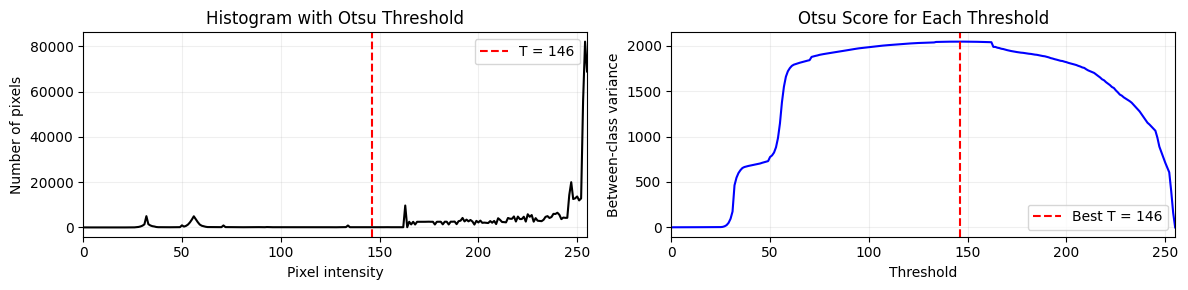

In [11]:
T, scores = otsu(hist)

print(f"Best threshold from Otsu: {T}")
print(f"Maximum Otsu score: {scores[T]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3))

axes[0].plot(hist, color="black")
axes[0].axvline(T, color="red", linestyle="--", label=f"T = {T}")
axes[0].set_title("Histogram with Otsu Threshold")
axes[0].set_xlabel("Pixel intensity")
axes[0].set_ylabel("Number of pixels")
axes[0].set_xlim([0, 255])
axes[0].grid(alpha=0.2)
axes[0].legend()

axes[1].plot(scores, color="blue")
axes[1].axvline(T, color="red", linestyle="--", label=f"Best T = {T}")
axes[1].set_title("Otsu Score for Each Threshold")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Between-class variance")
axes[1].set_xlim([0, 255])
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()


10. **<span style='color:lightgreen;'>Apply Threshold เพื่อสร้าง Binary Image</span>**

เมื่อได้ threshold จาก Otsu แล้ว นำค่า `T` ไปสร้าง binary image ด้วยกติกาเดียวกับ `cv2.THRESH_BINARY`

```text
ถ้า pixel > T  -> 255
ถ้า pixel <= T -> 0
```

cell นี้ตรวจสอบด้วยว่า binary image ที่สร้างเองให้ผลเหมือนกับ OpenCV หรือไม่


Threshold used by OpenCV: 146.0
Manual result equals OpenCV: True


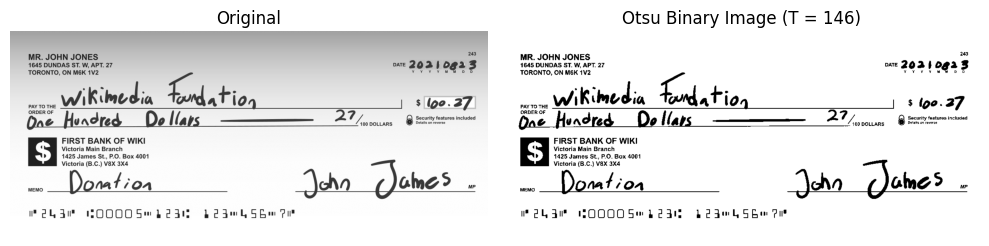

In [12]:
bin_img = to_bin(img, T)
ret, bin_cv = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)

print(f"Threshold used by OpenCV: {ret}")
print("Manual result equals OpenCV:", np.array_equal(bin_img, bin_cv))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(bin_img, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Otsu Binary Image (T = {T})")
axes[1].axis("off")

plt.tight_layout()
plt.show()


11. **<span style='color:lightgreen;'>ตัวอย่างเสริม: เปรียบเทียบ Threshold ที่เลือกเองกับ Otsu</span>**

เพื่อให้เห็นความต่าง ลองเทียบผลจาก threshold ที่เลือกเอง 2 ค่า กับ threshold ที่ Otsu เลือกให้อัตโนมัติ

ตัวอย่างนี้ช่วยเน้นว่า Otsu มีประโยชน์เมื่อเราไม่ต้องการเลือก threshold ด้วยสายตาทุกครั้ง


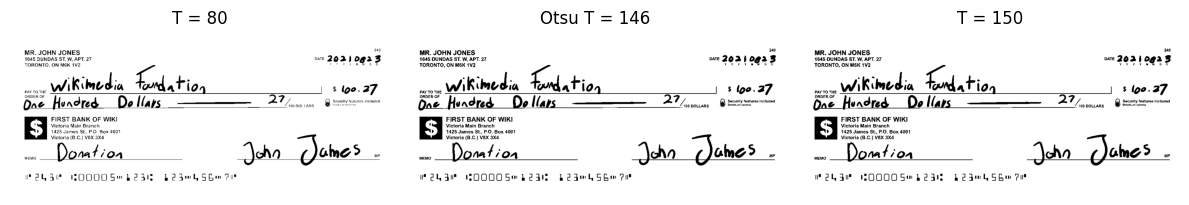

In [13]:
Ts = [80, T, 150]
labels = ["T = 80", f"Otsu T = {T}", "T = 150"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, t, label in zip(axes, Ts, labels):
    ax.imshow(to_bin(img, t), cmap="gray", vmin=0, vmax=255)
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()


#### <span style='color:Tomato;'>สรุปท้ายบท</span>

Otsu Algorithm เป็นเทคนิค thresholding แบบอัตโนมัติที่เลือกค่า `T` จาก histogram โดยพิจารณาว่า threshold ใดแยก pixel ออกเป็นสองกลุ่มได้ดีที่สุด

สิ่งที่ควรจำคือ

- แปลง histogram เป็น probability
- ทดลอง threshold หลายค่า
- แบ่ง pixel เป็นสองกลุ่มด้วย `T`
- คำนวณ `w0`, `w1`, `m0`, `m1`
- คำนวณ `sb = w0 * w1 * (m0 - m1)^2`
- เลือก `T` ที่ทำให้ `sb` สูงสุด

หลังจากเข้าใจ Otsu แล้ว นักศึกษาจะเห็นความเชื่อมโยงระหว่าง histogram, probability, ค่าเฉลี่ย และการแยก foreground/background ได้ชัดเจนขึ้น


In [17]:
ret1, otsu_thresh = cv2.threshold(img,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU) #result is the same my method otsu(hist)
ret2, otsu_thresh = cv2.threshold(img,128,255,cv2.THRESH_BINARY) #fixed threashold(128) if u not use + method cv2.THRESH_OTSU
print(ret1)  

146.0
